# Step 8: burn maps for the Black Cove Complex

**Goal:** turn before and after photos into a burn map, the same way Step 2 made flood maps.

New words:
- **NBR (Normalized Burn Ratio):** one score per pixel for "how green and alive". Living leaves are bright in near-infrared and dark in shortwave infrared, so NBR is high. Burned ground is the reverse.
- **dNBR:** NBR before minus NBR after. A big positive number means the score fell: burned.
- **Cutoff:** the dNBR value above which we call a pixel burned.

We make the map from **two pairs of photos** and compare:

| Pair | Before | After | Good | Bad |
|---|---|---|---|---|
| April | Sentinel-2, March 11 | Sentinel-2, April 12 | Fire had stopped | Some cloud; trees leafing out |
| March 26 | Landsat, March 18 | Landsat, March 26 | 100% clear | Fire still growing |

Each pair uses one satellite, so a change comes from the ground, not from a camera change.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np
import pandas as pd
import hls, fires
step8 = importlib.import_module('08_burn_maps')  # reuse the script's functions
# The script saves pictures to files only. This line also shows them here in the notebook.
%matplotlib inline
hls.login();

## Read the photos and compute the burn score
For each photo we read near-infrared and shortwave infrared inside the box, compute NBR, and blank out cloud, shadow and water.

In [2]:
bbox = fires.box_around(fires.outline(step8.FIRE))
all_data = {name: step8.load_pair(bbox, pair) for name, pair in step8.PAIRS.items()}
for name, d in all_data.items():
    u = d['usable']
    print(f"{name} pair: usable {u.mean():.0%} of the box; median NBR before "
          f"{np.median(d['before']['nbr'].values[u]):.3f}, after {np.median(d['after']['nbr'].values[u]):.3f}")

April pair: usable 78% of the box; median NBR before 0.122, after 0.323
March 26 pair: usable 99% of the box; median NBR before 0.144, after 0.152


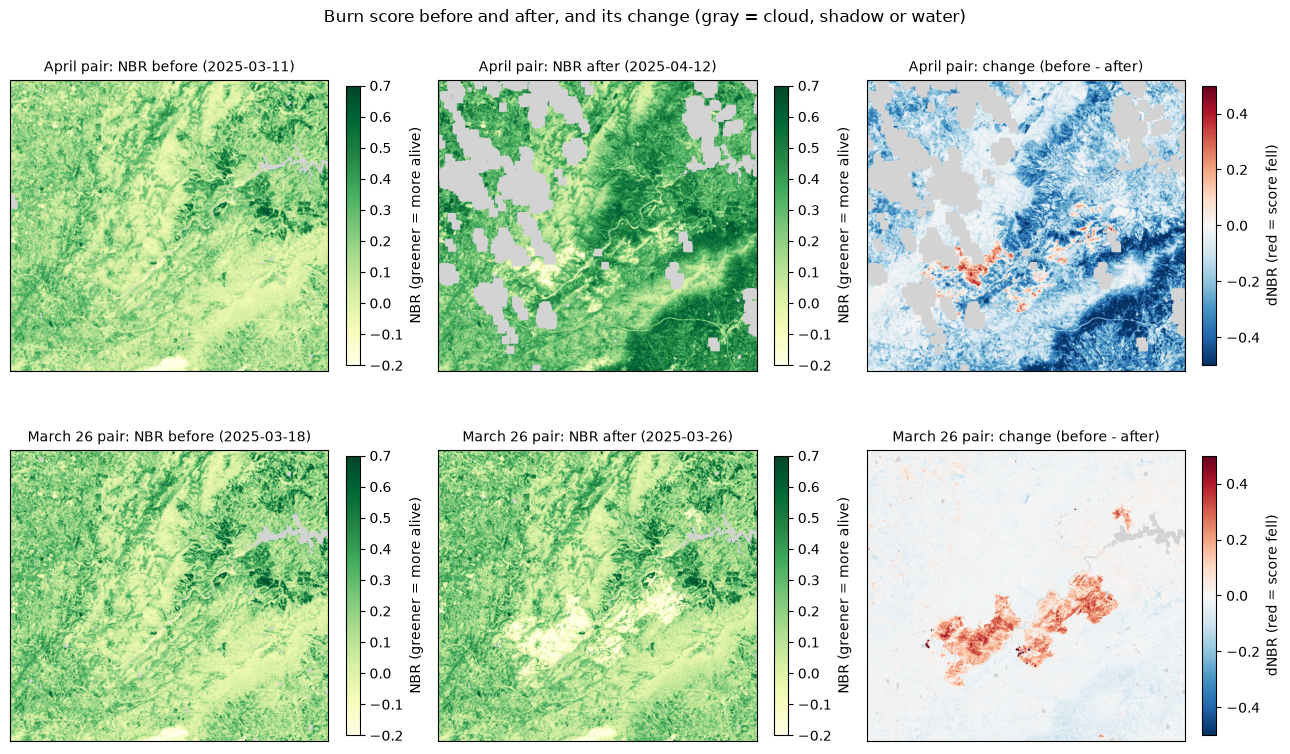

In [3]:
step8.plot_nbr(all_data, '../figures/08_nbr_before_after.png');

**What to notice**
- **March 26 pair (bottom row):** almost nothing changed except the burn, which shows as a red patch.
- **April pair (top row):** the whole box got greener in one month. The typical pixel's score went *up* (blue), because spring leaves came out. The burn shows as a pale and red patch inside a blue landscape.

## Choosing a cutoff, without looking at the outline
Two cutoffs per pair:
1. **Textbook:** dNBR above +0.10 counts as burned (the standard severity table).
2. **Histogram (triangle method):** most pixels did not burn, so the histogram is one big pile with a tail to the right. Stretch a string from the top of the pile to the end of the tail. The cutoff is where the histogram sags furthest below the string: the foot of the pile.

Neither one uses the official outline, so the outline stays a fair judge for the next step.

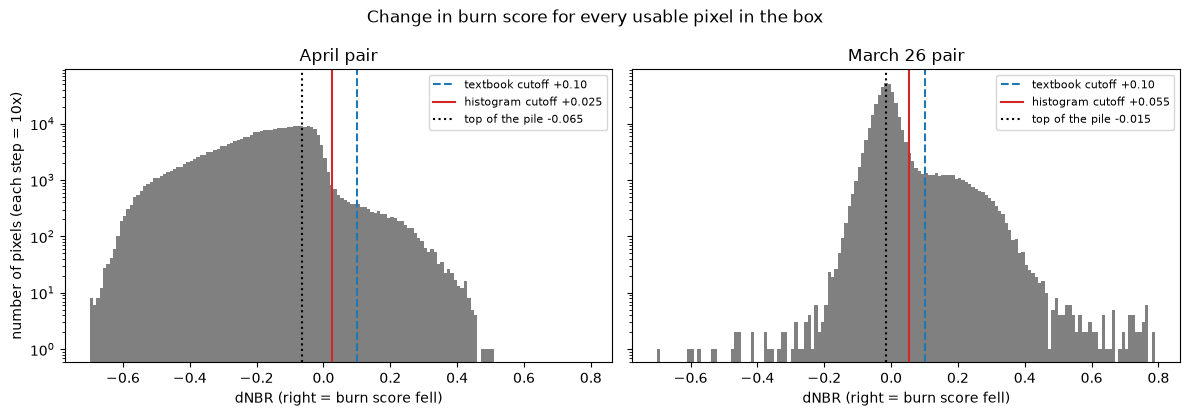

In [4]:
all_maps = {name: step8.make_maps(d) for name, d in all_data.items()}
step8.plot_histograms(all_data, all_maps, '../figures/08_histograms.png');

The side axis is stretched (each step up is 10 times more pixels) so the small burn tail stays visible.

The April pile sits left of zero and is very wide: fields, pines and leafy forest all greened up by different amounts.

## The four burn maps

In [5]:
step8.area_table(all_data, all_maps)

,pair,cutoff,dNBR cutoff,pile peak,burned km2,box usable
0,April,textbook,0.100,-0.065,4.4,78%
1,April,histogram,0.025,-0.065,7.7,78%
2,March 26,textbook,0.100,-0.015,19.8,99%
3,March 26,histogram,0.055,-0.015,26.9,99%


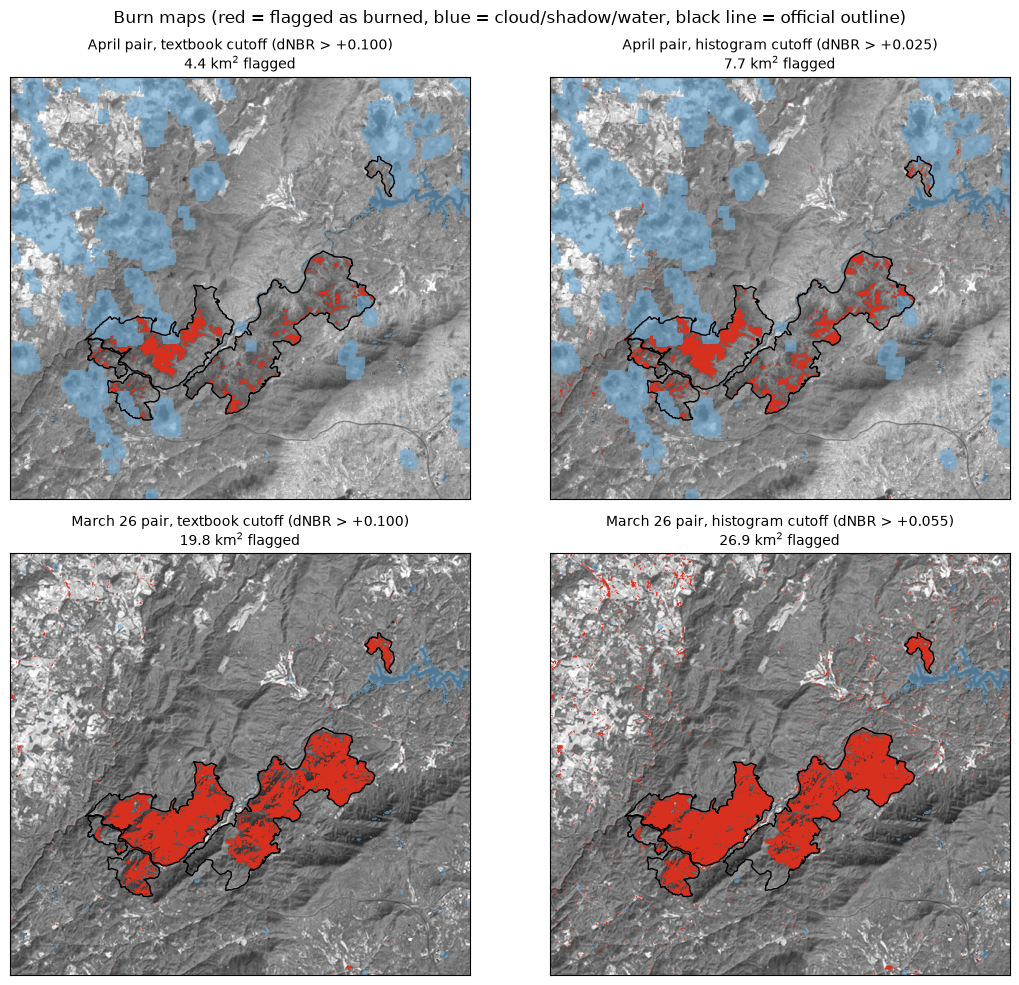

In [6]:
step8.plot_maps(all_data, all_maps, '../figures/08_burn_maps_compared.png');

How much do the April map and the March 26 map agree (histogram cutoffs, counted only where both pairs could see the ground)?

In [7]:
both_usable = all_data['April']['usable'] & all_data['March 26']['usable']
step8.overlap(all_maps['April']['maps']['histogram'], all_maps['March 26']['maps']['histogram'], both_usable)

{'both km2': 6.2,
 'only first km2': 1.5,
 'only second km2': 17.3,
 'overlap': 0.25}

## What we learned
- **The textbook cutoff fails on the April pair.** It flags 4.4 km²; the official burn is 31 km². In one month the whole landscape greened up, so "no change" is no longer at zero. It is the leaf season getting in the way, like blackwater did for the textbook water index.
- **A histogram cutoff helps a little, not enough.** It flags 7.7 km² in April. One cutoff for the whole box cannot work when fields, pines and leafy forest each changed by a different amount.
- **The March 26 pair is much cleaner:** 19.8 km² (textbook) and 26.9 km² (histogram). But the fire was still growing, so the lower-left lobe of the outline is missing, and the lower cutoff adds speckles on farmland.
- **The two maps overlap only 25%.** Almost everything April flags, March 26 flags too (6.2 of 7.7 km²). April simply misses most of the burn.
- **The April burn is not invisible.** In the change picture it is pale and red inside a deep-blue forest. It stands out against its *neighbors*. That is the idea for the next step: compare each burned pixel with nearby unburned forest instead of with zero.
- **Not graded yet.** The outline is drawn on the maps for the eye only. Measured "caught" and "right" scores come next.